<center><h1>Xia_Iris_HW5</h1></center>
<br>
<br>

Name: Iris Xia
<br>
Github Username: xd11997
<br>
USC ID: 1152659547

## 1. Decision Trees as Interpretable Models

Import packages

In [1]:
import pandas as pd
import numpy as np
from sklearn.tree import DecisionTreeClassifier
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import plot_tree
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LassoCV
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import Lasso
from sklearn.decomposition import PCA
from xgboost import XGBRegressor


### (a) Obtain Data

Get the Accute Inamations Data Set

In [2]:
file = "../../HW5/data/diagnosis.data"

df = pd.read_csv(file, sep="\t", header=None, decimal=",", encoding = "utf-16")

print(df.shape)
df.head()


(120, 8)


,0,1,2,3,4,5,6,7
0,35.5,no,yes,no,no,no,no,no
1,35.9,no,no,yes,yes,yes,yes,no
2,35.9,no,yes,no,no,no,no,no
3,36.0,no,no,yes,yes,yes,yes,no
4,36.0,no,yes,no,no,no,no,no


In [7]:
df.columns = [
    "Temperature",
    "Nausea",
    "Lumbar_pain",
    "Urine_pushing",
    "Micturition_pains",
    "Burning_of_urethra",
    "Bladder_inflammation",
    "Nephritis"
]

### (b) Build a decision tree

/var/folders/bn/snz6hdrs7gbfh48m_qnfs_dr0000gn/T/ipykernel_28287/2843579287.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_encoded = df.replace({"yes": 1, "no": 0}).infer_objects(copy=False)


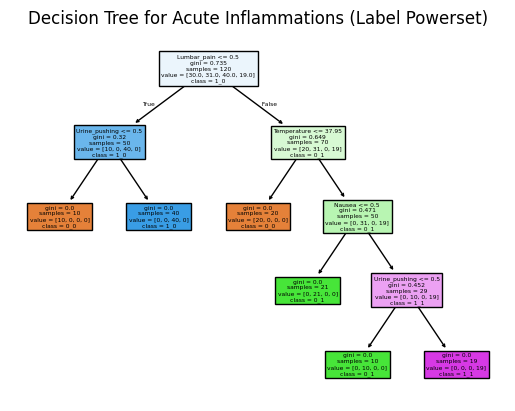

In [9]:
df_encoded = df.replace({"yes": 1, "no": 0}).infer_objects(copy=False)

X = df_encoded.iloc[:, :6]
Y = (df_encoded.iloc[:, 6].astype(str)+"_"+df_encoded.iloc[:, 7].astype(str))

clf = DecisionTreeClassifier(random_state=42)
clf.fit(X, Y)

plot_tree(clf, feature_names=X.columns, class_names=clf.classes_, filled=True)
plt.title("Decision Tree for Acute Inflammations (Label Powerset)")
plt.show()

### (c) Convert the decision rules

Rule 1

IF Lumbar pain = No AND Urine pushing = No
THEN Class = 0_0

Rule 2

IF Lumbar pain = No AND Urine pushing = Yes
THEN Class = 1_0

Rule 3

IF Lumbar pain = Yes AND Temperature ≤ 37.95
THEN Class = 0_0

Rule 4

IF Lumbar pain = Yes AND Temperature > 37.95 AND Nausea = No
THEN Class = 0_1

Rule 5

IF Lumbar pain = Yes AND Temperature > 37.95 AND Nausea = Yes AND Urine pushing = No
THEN Class = 0_1

Rule 6

IF Lumbar pain = Yes AND Temperature > 37.95 AND Nausea = Yes AND Urine pushing = Yes
THEN Class = 1_1

### (d)

In [13]:
path = clf.cost_complexity_pruning_path(X, Y)

results = []
for alpha in path.ccp_alphas:
    tree = DecisionTreeClassifier(random_state=42, ccp_alpha=alpha)
    tree.fit(X, Y)
    results.append((alpha, tree.get_n_leaves(), tree.score(X, Y)))

for r in results:
    print(r)

(np.float64(0.0), np.int64(6), 1.0)
(np.float64(0.09816666666666667), np.int64(4), 0.8416666666666667)
(np.float64(0.13333333333333333), np.int64(3), 0.7583333333333333)
(np.float64(0.18199999999999997), np.int64(2), 0.5916666666666667)
(np.float64(0.22291666666666676), np.int64(1), 0.3333333333333333)


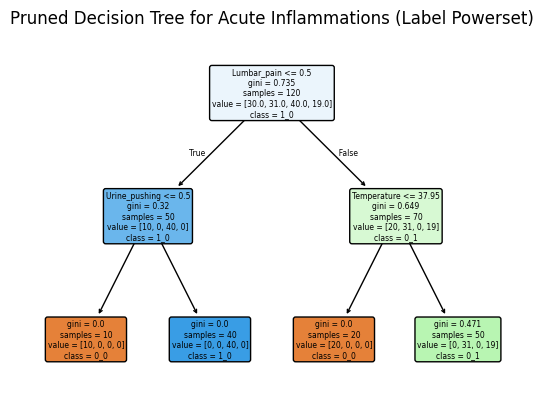

In [14]:
best_alpha = path.ccp_alphas[1]

pruned_tree = DecisionTreeClassifier(
    random_state=42,
    ccp_alpha=best_alpha
)
pruned_tree.fit(X, Y)

plot_tree(pruned_tree, feature_names = X.columns, class_names = pruned_tree.classes_, filled=True, rounded=True)
plt.title("Pruned Decision Tree for Acute Inflammations (Label Powerset)")
plt.show()

Rule 1

IF Lumbar pain = No AND Urine pushing = No
THEN Class = 0_0

Rule 2

IF Lumbar pain = No AND Urine pushing = Yes
THEN Class = 1_0

Rule 3

IF Lumbar pain = Yes AND Temperature ≤ 37.95
THEN Class = 0_0

Rule 4

IF Lumbar pain = Yes AND Temperature > 37.95
THEN Class = 0_1

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [3]:
df = pd.read_csv("../../HW5/data/communities.data", header=None, na_values="?")

train = df.iloc[:1495]
test = df.iloc[1495:]

print(df.shape)
print(train.shape)
print(test.shape)

(1994, 128)
(1495, 128)
(499, 128)


### (b) Missing values

In [20]:
drop_cols = [0, 1, 2, 3, 4]
train = train.drop(columns=drop_cols)
test = test.drop(columns=drop_cols)

X_train, y_train = train.iloc[:, :-1], train.iloc[:, -1]
X_test, y_test = test.iloc[:, :-1], test.iloc[:, -1]

imputer = SimpleImputer(strategy="median")

X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns
)

X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns
)

print("Missing values in training:", X_train.isna().sum().sum())
print("Missing values in test:", X_test.isna().sum().sum())

Missing values in training: 0
Missing values in test: 0


### (c) Plot a correlation matrix

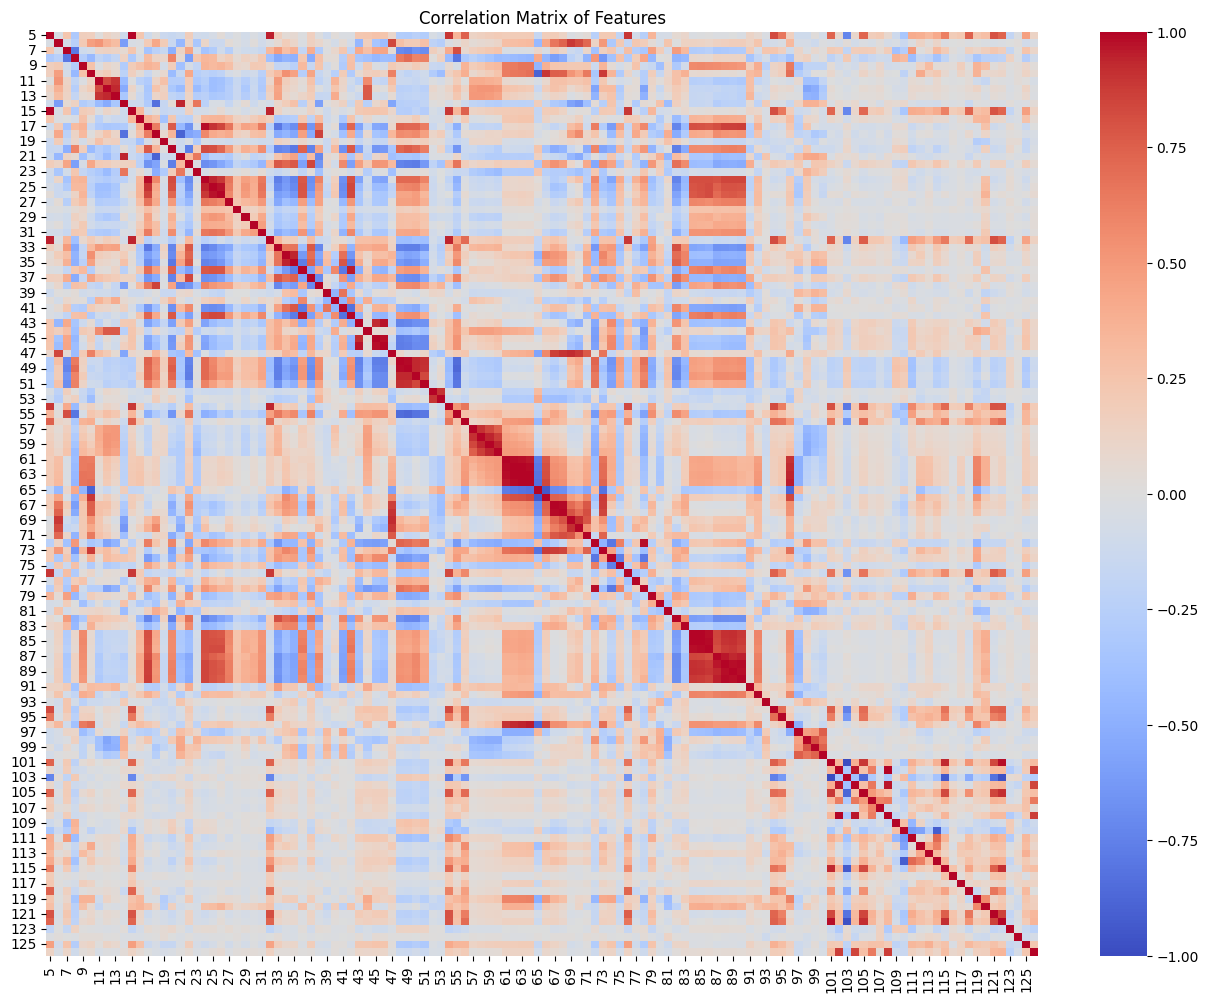

In [22]:
corr_matrix = X_train.corr()

plt.figure(figsize=(16, 12))
sns.heatmap(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Matrix of Features")
plt.show()

The correlation matrix shows that several groups of features exhibit strong positive or negative correlations, suggesting potential multicollinearity. However, many feature pairs have relatively weak linear correlations.

### (d) Calculate the Coefficient of Variation CV

In [23]:
cv = X_train.std() / X_train.mean()

print(cv.sort_values(ascending=False))

113    5.527059
95     4.292923
94     3.470952
54     3.058964
56     2.926635
         ...   
116    0.141021
109    0.129652
110    0.118727
123    0.112032
103    0.064414
Length: 122, dtype: float64


### (e) Scatter plots and box plots for highest CV features

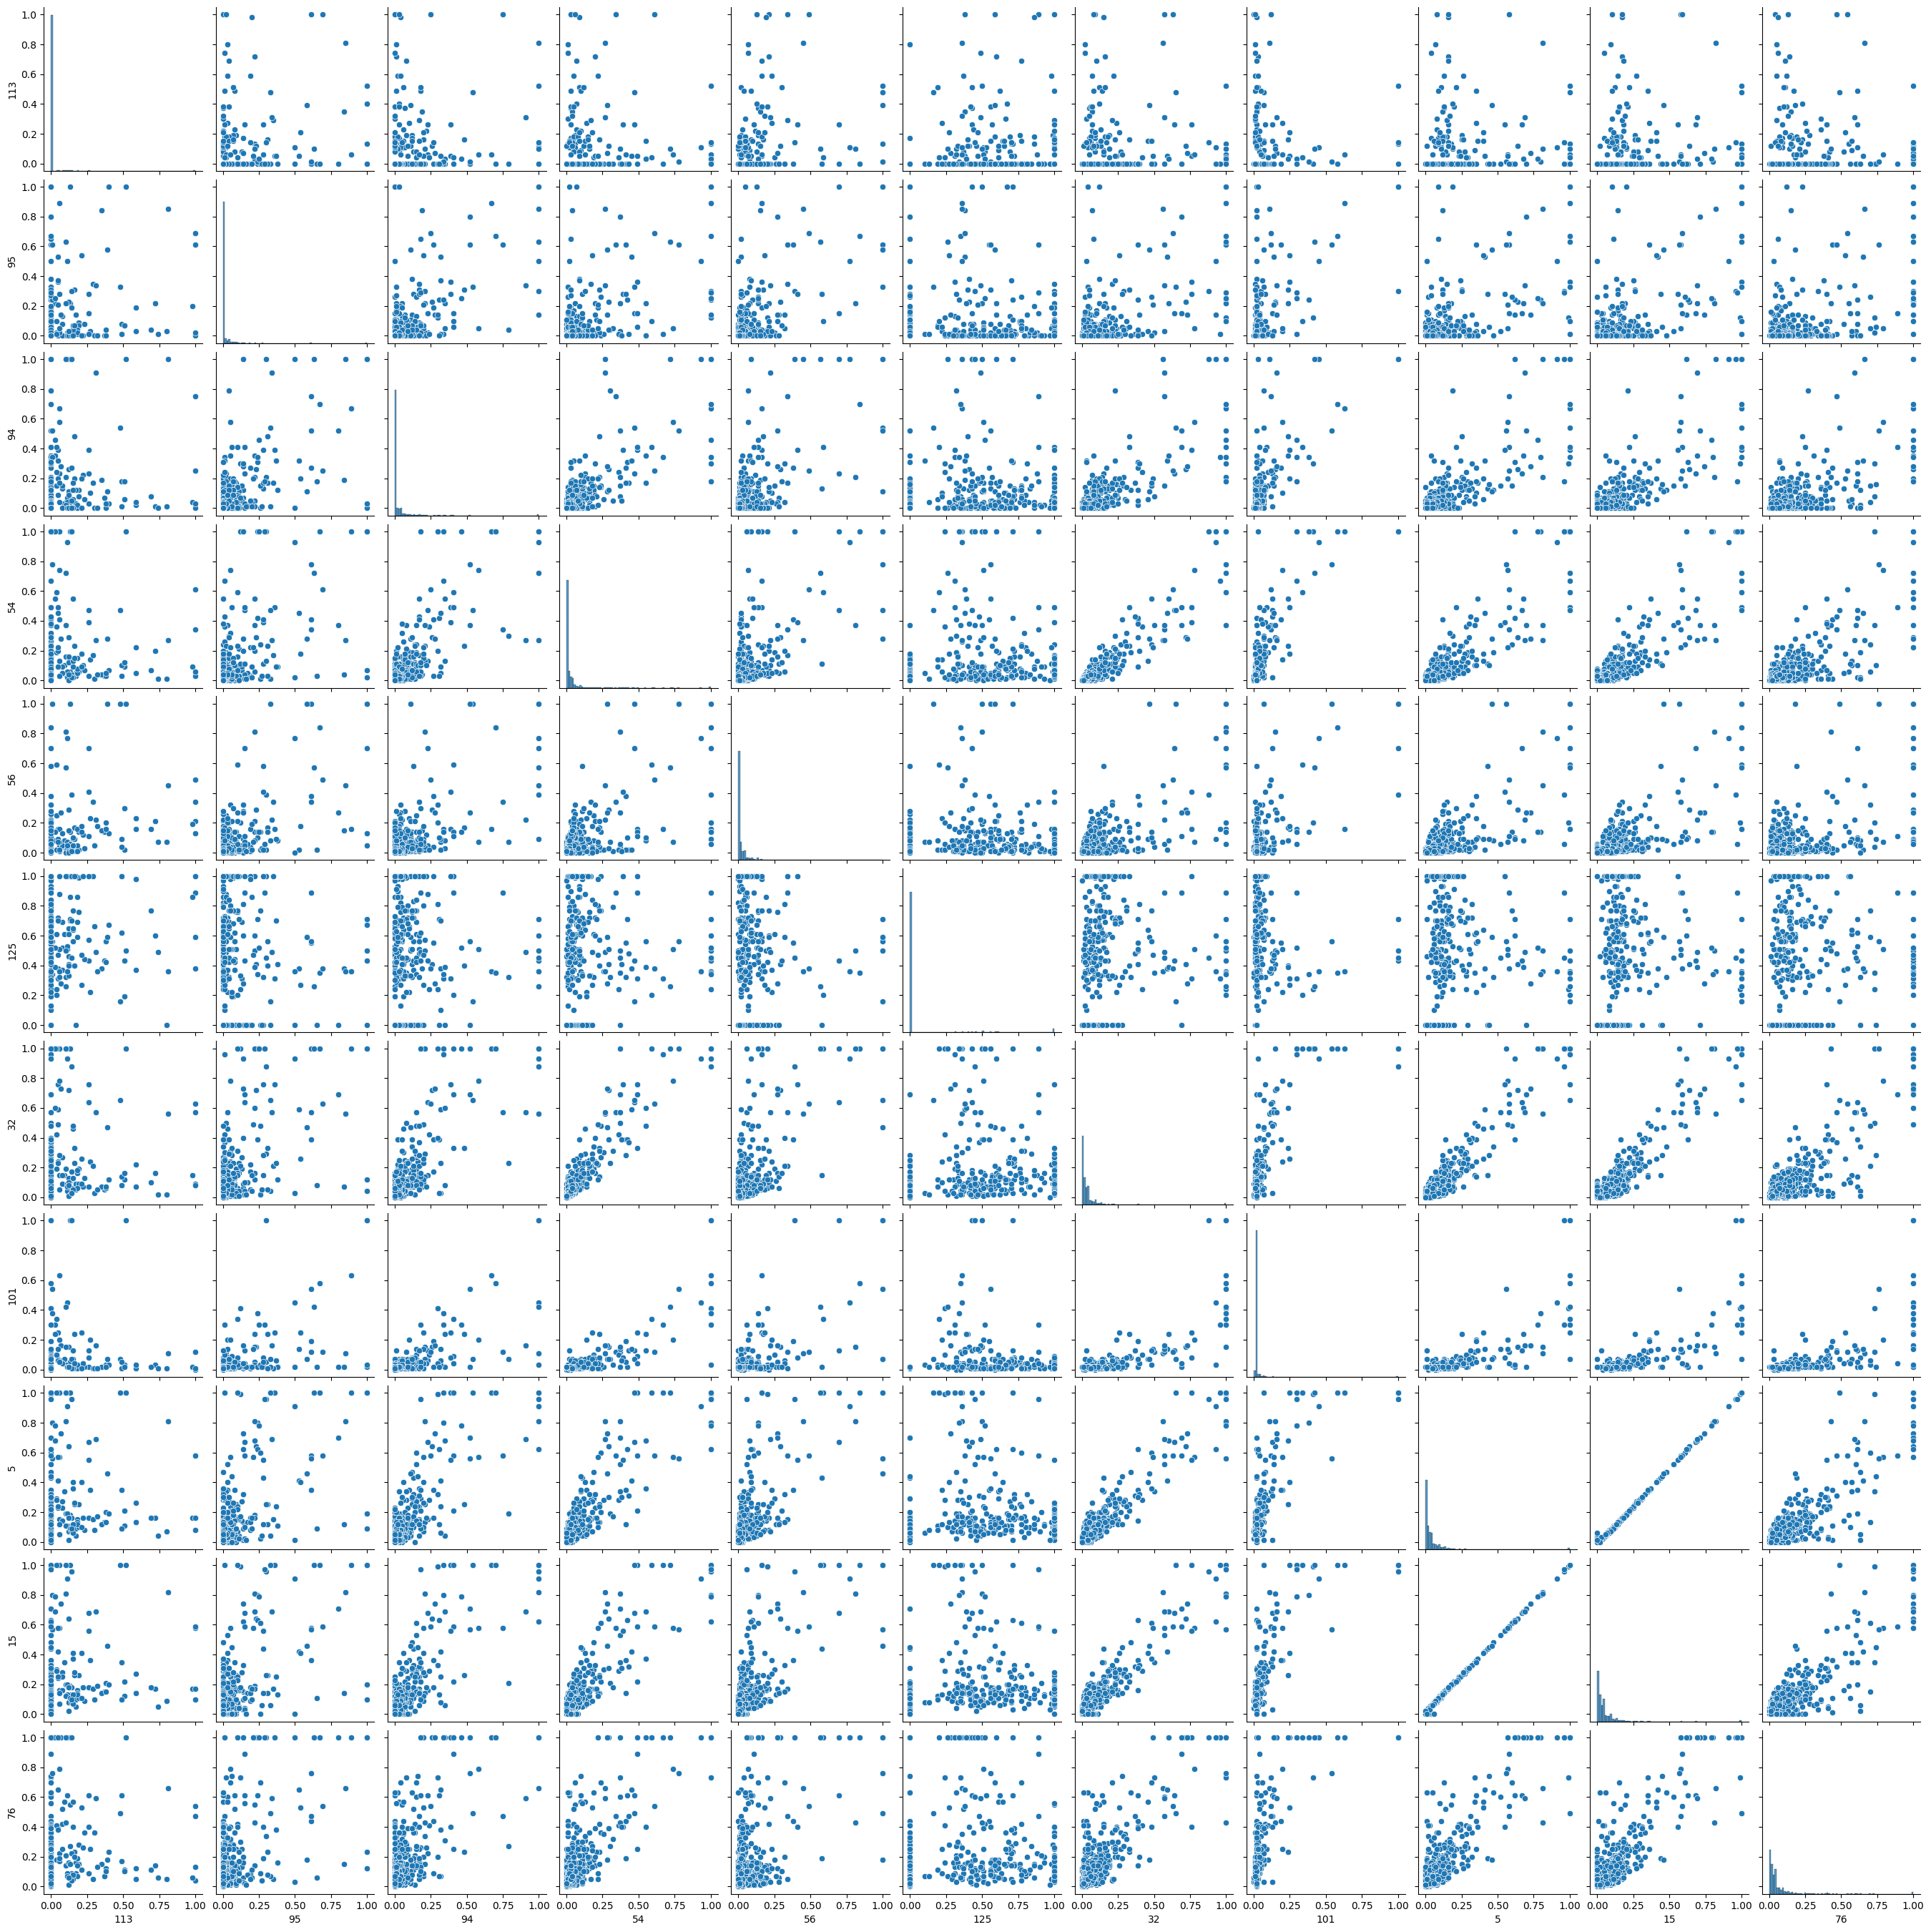

In [24]:
top_features = cv.sort_values(ascending=False).head(11).index
X_selected = X_train[top_features]

sns.pairplot(X_selected)
plt.show()

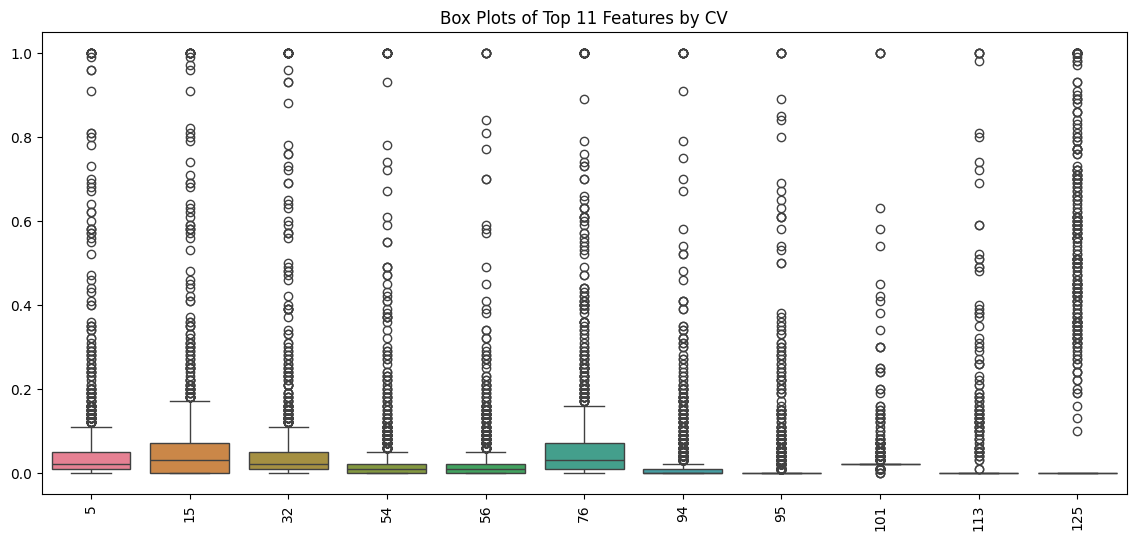

In [25]:
plt.figure(figsize=(14, 6))
sns.boxplot(data=X_selected)
plt.xticks(rotation=90)
plt.title("Box Plots of Top 11 Features by CV")
plt.show()

### (f) Fit a linear model

In [27]:
model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
test_mse = mean_squared_error(y_test, y_pred)

print("Test MSE:", test_mse)

Test MSE: 0.017966215426067345


### (g) Fit a ridge regression model

In [30]:
alphas = np.logspace(-4, 4, 100)

ridge = make_pipeline(
    StandardScaler(),
    RidgeCV(alphas=alphas, cv=5)
)

ridge.fit(X_train, y_train)

y_pred = ridge.predict(X_test)

print("Best lambda:", ridge.named_steps["ridgecv"].alpha_)
print("Test MSE:", mean_squared_error(y_test, y_pred))

Best lambda: 79.24828983539186
Test MSE: 0.017431130507402377


### (h) Fit a LASSO model

LASSO without Standardization

In [36]:
lasso = LassoCV(cv=5, max_iter=100000, random_state=42)
lasso.fit(X_train, y_train)

mse_raw = mean_squared_error(y_test, lasso.predict(X_test))
selected_raw = X_train.columns[lasso.coef_ != 0]

print("Best lambda:", lasso.alpha_)
print("Test MSE:", mse_raw)
print("Selected features:", list(selected_raw))
print("Number of selected features:", len(selected_raw))

Best lambda: 0.0001245408743775853
Test MSE: 0.01761776056977862
Selected features: [7, 9, 11, 12, 16, 18, 19, 20, 21, 22, 23, 26, 27, 28, 29, 30, 31, 33, 34, 38, 39, 41, 43, 44, 45, 49, 50, 51, 53, 54, 55, 56, 57, 60, 64, 66, 68, 69, 72, 73, 74, 75, 76, 77, 79, 80, 81, 82, 83, 84, 87, 90, 91, 92, 93, 94, 95, 96, 97, 99, 104, 107, 109, 111, 112, 113, 116, 117, 118, 119, 120, 121, 123, 124]
Number of selected features: 74


LASSO with Standardization

In [37]:
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("lasso", Lasso(max_iter=100000))
])

grid = GridSearchCV(
    pipeline,
    {"lasso__alpha": np.logspace(-5, 0, 60)},
    cv=5,
    scoring="neg_mean_squared_error"
)

grid.fit(X_train, y_train)

mse_scaled = mean_squared_error(y_test, grid.predict(X_test))
selected_scaled = X_train.columns[
    grid.best_estimator_.named_steps["lasso"].coef_ != 0
]

print("Best lambda:", grid.best_params_["lasso__alpha"])
print("Test MSE:", mse_scaled)
print("Selected features:", list(selected_scaled))
print("Number of selected features:", len(selected_scaled))

Best lambda: 0.0007318242219076174
Test MSE: 0.017690683395116265
Selected features: [7, 9, 11, 12, 16, 18, 19, 20, 21, 22, 23, 26, 27, 28, 29, 30, 31, 33, 34, 38, 39, 43, 44, 45, 49, 50, 51, 53, 54, 55, 56, 58, 60, 64, 66, 68, 69, 72, 73, 74, 75, 76, 77, 79, 80, 81, 82, 83, 87, 90, 91, 92, 93, 94, 95, 96, 99, 104, 105, 107, 109, 111, 112, 113, 115, 116, 117, 118, 119, 120, 121, 123, 124]
Number of selected features: 73


In [38]:
print("LASSO without standardization:", mse_raw)
print("LASSO with standardization:", mse_scaled)

LASSO without standardization: 0.01761776056977862
LASSO with standardization: 0.017690683395116265


Both LASSO models achieved slightly lower test MSE than OLS regression. LASSO without standardization performed marginally better. The results suggest that standardization did not improve predictive performance on this dataset.

### (i) Fit a PCR model

In [40]:
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA()),
    ("regression", LinearRegression())
])

grid = GridSearchCV(
    pipeline,
    {"pca__n_components": range(1, X_train.shape[1] + 1)},
    cv=5,
    scoring="neg_mean_squared_error"
)

grid.fit(X_train, y_train)

y_pred = grid.predict(X_test)

print("Best M:", grid.best_params_["pca__n_components"])
print("Test MSE:", mean_squared_error(y_test, y_pred))

Best M: 95
Test MSE: 0.018296345367709833


### (j) Fit a boosting tree

In [42]:
model = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=1
)

grid = GridSearchCV(
    model,
    {"reg_alpha": np.logspace(-4, 2, 20)},
    cv=5,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

grid.fit(X_train, y_train)

y_pred = grid.predict(X_test)

print("Best alpha:", grid.best_params_["reg_alpha"])
print("Test MSE:", mean_squared_error(y_test, y_pred))

Best alpha: 5.455594781168514
Test MSE: 0.01715816044041349
